# Why you should use a framework: Titanic with fastai

## What are we building?
A model that looks at a Titanic passenger (age, sex, ticket class, fare, family on board, ...) and predicts **whether they survived (1) or not (0)**.

This is exactly the same problem as `pytorch_from_scratch.ipynb`. The difference is *how* we solve it.

## Why are we building it again?
In the from-scratch notebook we did every step by hand: filling blanks, turning words into 0/1 columns, scaling columns, inventing random starting numbers, guessing a learning rate, writing the training loop, and re-doing all the preparation for the test set (where we hit several bugs).

Here we solve the same problem with **fastai**, a library built on top of PyTorch. The goal is not a better score (the dataset is tiny, so scores will be similar). The goal is to see:

1. **What a framework automates**, so you know what each hand-written piece was replaced by.
2. **What it hides**, so you remember what is happening under the hood.
3. **How much easier it is to try new ideas** (we will add new features and build an ensemble with very little code).



## Map: what you wrote by hand → what fastai does for you

| Step | From scratch (previous notebook) | fastai (this notebook) |
|---|---|---|
| Fill blanks | `df.fillna(modes)` | `FillMissing` |
| Words → numbers | `pd.get_dummies(...)` | `Categorify` (+ embeddings) |
| Scale columns | `t_indep / vals` | `Normalize` |
| Train/validation split | `torch.randperm` + slicing | `RandomSplitter` |
| Tables → batches of tensors | `tensor(df[...].values)` | `TabularPandas` + `.dataloaders()` |
| Model | `init_coeffs` + `calc_preds` | `tabular_learner` |
| Pick a learning rate | trial and error (`lr=100`) | `learn.lr_find()` |
| Training loop | `one_epoch` + `train_model` | `learn.fit()` |
| Prepare the test set | repeat every step by hand | `learn.dls.test_dl()` |

## How to read this notebook
Each code cell has a short explanation **before** it (what and why) and a comment on **every important line** inside it.

**Before you start:** fastai is installed in this project's `.venv`, and the `titanic` data folder from the previous notebook is reused. When you import fastai on Python 3.14 you may see a `FutureWarning` about `torch.jit`. It is harmless and can be ignored.

## 1. Set up: find the data

First we decide where the Titanic files are. On Kaggle's servers they are already provided; on your own computer we download them once with the Kaggle API (using the token you saved earlier) and reuse them afterwards.

In [11]:
from pathlib import Path   # Path builds file paths that work on any operating system
import os                  # os lets us read environment variables

# Kaggle's servers set this variable; on your own computer it is empty ('')
iskaggle = os.environ.get('KAGGLE_KERNEL_RUN_TYPE', '')

if iskaggle:
    path = Path('../input/titanic')    # on Kaggle the competition data is already here
else:
    path = Path('titanic')             # locally: a folder named 'titanic' next to this notebook
    if not path.exists():              # only download if we don't have it yet
        import zipfile, kaggle
        kaggle.api.competition_download_cli(str(path))   # downloads titanic.zip from Kaggle
        zipfile.ZipFile(f'{path}.zip').extractall(path)  # unzips it into the folder

path   # show which folder we will read from

Path('titanic')

### Import fastai

`from fastai.tabular.all import *` brings in everything we need for *tabular* data (data that fits in a table with rows and columns, like a spreadsheet).

Normally a `*` import is discouraged in Python because you can't tell where names come from. fastai is designed to be used this way in notebooks: the star import also gives us `pd` (pandas), `np` (numpy) and `torch`, plus fastai tools such as `TabularPandas`, `Categorify` and `tabular_learner`. That is why we don't import those separately below.

Two small settings follow:
- `pd.options.display.float_format` makes pandas show numbers with 2 decimals so tables stay readable.
- `set_seed(42)` fixes the random number generators (Python, numpy and PyTorch) so results are similar each time you run the notebook. The 42 is an arbitrary choice.

In [12]:
from fastai.tabular.all import *   # fastai's tabular tools (also gives us pd, np and torch)

pd.options.display.float_format = '{:.2f}'.format   # show floats with 2 decimal places
set_seed(42)                                         # make random choices repeatable

## 2. Prep the data

### Load the training data
Same as before: one row per passenger, and a `Survived` column (1 = lived, 0 = died) which is what we want to predict.

In [13]:
df = pd.read_csv(path/'train.csv')   # path/'train.csv' joins the folder and file name; read_csv loads it as a table
df.head()                            # show the first 5 rows

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.00,1,0,A/5 21171,7.25,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.00,1,0,PC 17599,71.28,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.00,0,0,STON/O2. 3101282,7.92,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.00,1,0,113803,53.10,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.00,0,0,373450,8.05,NaN,S


### Create new features (feature engineering)

In the from-scratch notebook every extra column meant extra work: dummy variables, scaling, missing values. With fastai those steps are automatic, so adding ideas is cheap. Let's add several new columns (borrowed from a well-known [Titanic feature engineering notebook](https://www.kaggle.com/code/gunesevitan/titanic-advanced-feature-engineering-tutorial/)).

| New column | What it holds | Why it might help |
|---|---|---|
| `LogFare` | log of the fare | squashes the huge fares so a few rich passengers don't dominate (same as before) |
| `Deck` | deck letter from the cabin, grouped | where on the ship someone stayed may matter |
| `Family` | siblings/spouses + parents/children | travelling with family may change survival chances |
| `Alone` | True if `Family` is 0 | a simple yes/no version of the above |
| `TicketFreq` | how many passengers share this ticket | people on the same ticket usually travel together |
| `Title` | Mr / Miss / Mrs / Master from the name | a hint of age, sex and social status |

First, a tiny demo of how we get the title out of a name, so the one-line version below makes sense:

In [14]:
example = "Braund, Mr. Owen Harris"                    # names look like "Surname, Title. Given names"
print(example.split(', '))                             # split at ', '  ->  ['Braund', 'Mr. Owen Harris']
print(example.split(', ')[1])                          # take the second piece -> 'Mr. Owen Harris'
print(example.split(', ')[1].split('.')[0])            # split at '.' and take the first piece -> 'Mr'

['Braund', 'Mr. Owen Harris']
Mr. Owen Harris
Mr


In [15]:
def add_features(df):
    # np.log1p(x) = log(1 + x). The +1 means a fare of 0 doesn't break the log
    df['LogFare'] = np.log1p(df['Fare'])

    # Cabin looks like 'C85'. .str[0] takes the first letter (the deck). .map() swaps each letter for a group
    # name from the dictionary. Letters not in the dictionary (and missing cabins) become NaN (blank)
    df['Deck'] = df.Cabin.str[0].map(dict(A="ABC", B="ABC", C="ABC", D="DE", E="DE", F="FG", G="FG"))

    # Family size = siblings/spouses on board + parents/children on board
    df['Family'] = df.SibSp + df.Parch

    # True if the passenger has no family on board. (True/False will be treated as 1/0)
    df['Alone'] = df.Family == 0

    # groupby('Ticket') puts passengers with the same ticket number together;
    # transform('count') writes the size of each group back onto every row of that group
    df['TicketFreq'] = df.groupby('Ticket')['Ticket'].transform('count')

    # Title: split the name at ', ' and take the 2nd piece, then split at '.' and take the 1st piece.
    # expand=True turns the pieces into separate columns so [1] / [0] pick a column
    df['Title'] = df.Name.str.split(', ', expand=True)[1].str.split('.', expand=True)[0]

    # Keep only the 4 common titles. Rare ones (Dr, Rev, Col, ...) are not in the dictionary, so they become NaN
    df['Title'] = df.Title.map(dict(Mr="Mr", Miss="Miss", Mrs="Mrs", Master="Master"))

add_features(df)   # the function changes df in place (adds the new columns directly to it)
df[['Name', 'Title', 'Cabin', 'Deck', 'Family', 'Alone', 'TicketFreq']].head(8)

,Name,Title,Cabin,Deck,Family,Alone,TicketFreq
0,"Braund, Mr. Owen Harris",Mr,NaN,NaN,1,False,1
1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",Mrs,C85,ABC,1,False,1
2,"Heikkinen, Miss. Laina",Miss,NaN,NaN,0,True,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Mrs,C123,ABC,1,False,2
4,"Allen, Mr. William Henry",Mr,NaN,NaN,0,True,1
5,"Moran, Mr. James",Mr,NaN,NaN,0,True,1
6,"McCarthy, Mr. Timothy J",Mr,E46,DE,0,True,1
7,"Palsson, Master. Gosta Leonard",Master,NaN,NaN,4,False,4


Missing values are normal here. Many passengers have no cabin, and rare titles were dropped on purpose. We don't fix these ourselves: fastai will handle blanks in the next steps. Let's just see how many there are:

In [16]:
df[['Deck', 'Title']].isna().sum()   # isna() marks blanks as True; sum() counts them per column

Deck     688
Title     27
dtype: int64

### Split into training and validation sets

We keep 20% of the passengers hidden during training and use them only to check the model. If we tested on the same passengers we trained on, a model could just memorise them and look better than it really is.

In the from-scratch notebook we wrote this ourselves with `torch.randperm`. fastai's `RandomSplitter` is the library version of that idea:
- `RandomSplitter(seed=42)` creates a splitting function (by default 20% goes to validation). The seed makes the split repeatable.
- Calling it with `(df)` returns two lists of row numbers: `(training rows, validation rows)`.

In [17]:
splits = RandomSplitter(seed=42)(df)     # (list of training row numbers, list of validation row numbers)
len(splits[0]), len(splits[1])           # how many rows in each: training, validation

(713, 178)

### Get the data ready for training: one cell

This is where fastai replaces most of the hand-written preparation from the previous notebook.

`TabularPandas` takes the table and applies a list of *processors* (`procs`) in order:

| Processor | What it does | Replaces (from scratch) |
|---|---|---|
| `Categorify` | turns text categories into whole-number codes (and keeps a lookup of what each code means); also adds an `#na#` code for unknown/blank | `pd.get_dummies` |
| `FillMissing` | fills blanks in number columns with the median, and **adds a new yes/no column** (e.g. `Age_na`) recording which rows were blank | `df.fillna(modes)` |
| `Normalize` | rescales each number column: subtract its mean, divide by its standard deviation, using **training-set** numbers | `t_indep / vals` |

The other arguments:

| Argument | Meaning |
|---|---|
| `splits=splits` | which rows are for training and which for validation |
| `cat_names=[...]` | **categorical** inputs: columns whose values are labels (Sex, Pclass, Embarked, Deck, Title) |
| `cont_names=[...]` | **continuous** inputs: columns whose values are real numbers where size matters (Age, Fare, ...). `Alone` is True/False, but we treat it as a 0/1 number |
| `y_names="Survived"` | the column we want to predict (the *dependent variable*) |
| `y_block=CategoryBlock()` | the answer is a category (died / survived), so this is a **classification** problem, not predicting a quantity |

`.dataloaders(path=".")` then wraps the prepared table into **DataLoaders**: objects that hand the model the data in small shuffled groups called *batches* (64 rows at a time by default). `path="."` is just the folder where fastai may save files later.

In [18]:
dls = TabularPandas(
    df, splits=splits,                                   # the table and the train/validation split
    procs = [Categorify, FillMissing, Normalize],        # preparation steps, applied in this order
    cat_names=["Sex", "Pclass", "Embarked", "Deck", "Title"],                       # label-type inputs
    cont_names=['Age', 'SibSp', 'Parch', 'LogFare', 'Alone', 'TicketFreq', 'Family'],  # number-type inputs
    y_names="Survived",                                  # what we want to predict
    y_block = CategoryBlock(),                           # ...and it is a category (classification)
).dataloaders(path=".")                                  # turn it into batches the model can train on

c:\Users\Pranav\Documents\andrew-ng-ml-course\foundations\.venv\Lib\site-packages\fastai\torch_core.py:155: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  else as_tensor(x.values, **kwargs) if isinstance(x, (pd.Series, pd.DataFrame))


### Look at what fastai did to our data

`show_batch` displays a few rows in human-readable form. Below that, we peek at the *processed* values the model actually receives.

In [19]:
dls.show_batch(max_n=4)   # a few training rows, shown in readable form

,Sex,Pclass,Embarked,Deck,Title,Age_na,Age,SibSp,Parch,LogFare,Alone,TicketFreq,Family,Survived
0,male,3,S,#na#,Master,False,1.00,4.00,1.00,3.71,0.00,6.00,5.00,0
1,male,3,S,#na#,Mr,True,28.00,0.00,-0.00,2.19,1.00,1.00,-0.00,0
2,female,3,S,#na#,Miss,False,2.00,0.00,1.00,2.59,0.00,1.00,1.00,1
3,female,3,S,#na#,Miss,False,21.00,1.00,-0.00,2.38,0.00,1.00,1.00,0
4,female,2,S,#na#,Miss,False,13.00,0.00,1.00,3.02,0.00,2.00,1.00,1
5,male,3,S,FG,Mr,False,25.00,0.00,-0.00,2.16,1.00,1.00,-0.00,0
6,male,3,S,#na#,Mr,False,28.00,0.00,-0.00,4.05,1.00,7.00,-0.00,0
7,male,3,S,#na#,Master,False,11.00,5.00,2.00,3.87,0.00,6.00,7.00,0
8,male,2,S,#na#,Mr,True,28.00,0.00,-0.00,0.00,1.00,1.00,-0.00,0
9,male,3,S,#na#,Mr,False,37.00,2.00,-0.00,2.19,0.00,1.00,2.00,0


In [20]:
# The same kind of rows, but as the model sees them (after Categorify / FillMissing / Normalize)
cols = ['Sex', 'Pclass', 'Embarked', 'Deck', 'Title', 'Age_na', 'Age', 'SibSp', 'Parch', 'LogFare', 'Alone', 'TicketFreq', 'Family']
dls.train_ds.items[cols].head(3)

,Sex,Pclass,Embarked,Deck,Title,Age_na,Age,SibSp,Parch,LogFare,Alone,TicketFreq,Family
788,2,3,3,0,1,1,-2.18,0.46,2.03,0.13,-1.26,0.16,1.34
525,2,3,2,0,3,1,0.86,-0.46,-0.46,-0.78,0.79,-0.58,-0.55
821,2,3,3,0,3,1,-0.18,-0.46,-0.46,-0.68,0.79,-0.58,-0.55


What to notice in the table above:

- **`Sex`, `Pclass`, `Embarked`, `Deck`, `Title` are now whole numbers.** `Categorify` replaced each label with a code. The cell below shows what the codes mean.
- **`Age`, `LogFare`, ... are now small numbers around 0 (some negative).** That is `Normalize` at work: values below the average become negative, above the average positive.
- **There is a new column `Age_na`.** `FillMissing` added it, and it is treated as a categorical input too. It tells the model which passengers had no recorded age, since "age unknown" may itself be informative.

In [21]:
print(dls.classes['Sex'])      # code 0 = '#na#' (unknown), 1 = 'female', 2 = 'male'
print(dls.classes['Title'])    # the title codes. '#na#' covers the rare titles we dropped
print(dls.classes['Deck'])     # '#na#' here is mostly passengers with no cabin recorded

['#na#', 'female', 'male']
['#na#', 'Master', 'Miss', 'Mr', 'Mrs']
['#na#', 'ABC', 'DE', 'FG']


## 3. Train the model

### Create the Learner
A fastai **Learner** bundles everything needed to train: the data (`dls`), the model, the loss function, the optimizer and the metrics.

`tabular_learner(dls, metrics=accuracy, layers=[10,10])`:
- `dls`: the data we just prepared. fastai reads it to work out how big the model's input and output should be.
- `layers=[10,10]`: two hidden layers with 10 neurons each. This is the same idea as the `hiddens = [10, 10]` network you built by hand.
- `metrics=accuracy`: print the fraction of correct predictions on the validation set after every epoch. (The *loss* is what the model learns from. The *metric* is what we humans want to read.)

Everything else is chosen for us. We never had to invent random starting coefficients, pick a loss function, or write an update step. fastai picks a suitable loss for classification and uses the Adam optimizer, a smarter version of the "nudge each coefficient by gradient × learning rate" step you wrote by hand.

In [22]:
learn = tabular_learner(dls, metrics=accuracy, layers=[10,10])

### Peek inside the model

Printing the model shows what fastai built. Compare it with your hand-made network.

In [13]:
learn.model

TabularModel(
  (embeds): ModuleList(
    (0): Embedding(3, 3)
    (1-3): 3 x Embedding(4, 3)
    (4): Embedding(5, 4)
    (5): Embedding(3, 3)
  )
  (emb_drop): Dropout(p=0.0, inplace=False)
  (bn_cont): BatchNorm1d(7, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (layers): Sequential(
    (0): LinBnDrop(
      (0): Linear(in_features=26, out_features=10, bias=False)
      (1): ReLU(inplace=True)
      (2): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): LinBnDrop(
      (0): Linear(in_features=10, out_features=10, bias=False)
      (1): ReLU(inplace=True)
      (2): BatchNorm1d(10, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (2): LinBnDrop(
      (0): Linear(in_features=10, out_features=2, bias=True)
    )
  )
)

How to read that printout:

- **`embeds`: one `Embedding` per categorical column.** An embedding is a *learned lookup table*: each category gets a small vector of numbers that the model adjusts during training. For example `Embedding(3, 3)` for `Sex` means 3 possible codes (`#na#`, female, male), each represented by 3 learned numbers. In the from-scratch notebook we used fixed 0/1 dummy columns instead. Embeddings let the model learn how similar categories are.
- **`bn_cont`: BatchNorm on the continuous columns.** It keeps the number inputs on a steady scale while training.
- **`layers`: the hidden layers.** The first `Linear(in_features=26, out_features=10)` takes **26 numbers**: the 19 numbers coming out of the embeddings plus our 7 continuous columns. Each hidden layer is `Linear` (multiply by coefficients, like your `@`), then `ReLU` (replace negatives with 0, exactly like `F.relu` in your network), then `BatchNorm` (keeps values well-behaved).
- **The last `Linear(10, 2)` has 2 outputs**: one score for "died" and one for "survived". We will turn those into probabilities later. Your hand-made network had a single output with a sigmoid; this is the equivalent, written with two outputs.

### Find a good learning rate

The **learning rate** is the size of each nudge applied to the model's numbers. Too small and training crawls; too large and it overshoots and gets worse. In the from-scratch notebook we simply tried values (we ended up with a wild `lr=100`).

`learn.lr_find()` automates that search: it trains for a moment while *increasing* the learning rate from tiny to huge, recording the loss each time, and draws a graph of loss against learning rate. We want a learning rate where the loss is **falling steeply**, a bit before the point where it shoots back up.

`suggest_funcs=(slide, valley)` asks for two automatic suggestions (the two coloured dots on the graph), each found with a different rule of thumb. Both are reasonable starting points.

<div></div>

SuggestedLRs(slide=0.10000000149011612, valley=0.02290867641568184)

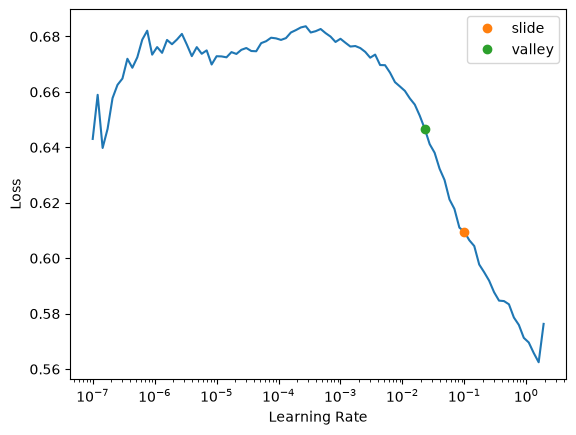

In [23]:
learn.lr_find(suggest_funcs=(slide, valley))   # plots loss vs learning rate and marks two suggested values

### Train

We pick a learning rate between the two suggestions. In our run they were about `0.02` (valley) and `0.1` (slide), so we use `0.03`. The exact suggestions can differ a little each time you run the notebook, and anything in that region works.

`learn.fit(16, lr=0.03)` runs **16 epochs**. One *epoch* is one full pass through all the training passengers. This single line replaces your `one_epoch`, `update_coeffs` and `train_model` functions.

In the table that appears:

| Column | Meaning |
|---|---|
| `train_loss` | how wrong the model is on the passengers it learns from |
| `valid_loss` | how wrong it is on the held-back validation passengers (the number that really matters) |
| `accuracy` | fraction of validation passengers predicted correctly |
| `time` | how long that epoch took |

If `train_loss` keeps falling but `valid_loss` starts rising, the model is **overfitting**: memorising the training passengers rather than learning general patterns.

In [24]:
learn.fit(16, lr=0.03)   # 16 passes over the training data, learning rate 0.03

epoch,train_loss,valid_loss,accuracy,time
0,0.519395,0.580710,0.629214,00:00
1,0.471296,0.493591,0.820225,00:00
2,0.455742,0.509791,0.792135,00:00
3,0.424257,0.473308,0.792135,00:00
4,0.417170,0.438961,0.825843,00:00
5,0.407982,0.441103,0.820225,00:00
6,0.401742,0.467240,0.792135,00:00
7,0.404638,0.438445,0.814607,00:00
8,0.397327,0.437268,0.808989,00:00
9,0.405645,0.409377,0.808989,00:00


**Reading the result.** The accuracy is close to what our hand-built model reached (about 0.83). That isn't surprising: this dataset is small and simple, and a plain linear model already does well. Notice also that the accuracy moves up and down a few points from epoch to epoch. There are only 178 validation passengers, so each person is worth about 0.56 percentage points of accuracy and the number is naturally noisy. Don't chase a single epoch's value.

The point of this notebook isn't a higher score yet. It's that all of this took about 10 lines of code.

## 4. Predict the test set and make a submission

fastai stores everything needed to prepare new data inside the learner: the category lookups, the medians used to fill blanks, and the means and standard deviations used to normalise. So for the test set we only redo the steps that are **our own** (loading the file, filling the missing fare, adding our features), and fastai handles the rest.

This fixes the mistake we ran into in the previous notebook: repeating the preparation by hand and getting it slightly different from training.

In [25]:
tst_df = pd.read_csv(path/'test.csv')        # the passengers we must predict (no 'Survived' column)
tst_df['Fare'] = tst_df.Fare.fillna(0)       # the test set has one blank Fare; set it to 0 (as before)
add_features(tst_df)                         # add the SAME extra columns we added to the training data

`learn.dls.test_dl(tst_df)` builds a DataLoader for new data by applying the **stored** processing steps (`Categorify`, `FillMissing`, `Normalize`) using what was learned from the *training* data. We never have to name those steps again.

In [27]:
tst_dl = learn.dls.test_dl(tst_df)   # prepare the test table exactly the way the training data was prepared

`learn.get_preds(dl=tst_dl)` runs the model on the test passengers. It returns two things: the predictions and the correct answers. A test set has no answers, so we ignore the second with `_`.

The predictions have **two columns** (shape: 418 passengers × 2). They are probabilities that add up to 1 per row: column 0 is the probability of *died* (class 0) and column 1 is the probability of *survived* (class 1).

In [28]:
preds, _ = learn.get_preds(dl=tst_dl)   # preds: one row per test passenger, two probability columns
print(preds.shape)                      # (418, 2)
print(dls.vocab)                        # the class order: [0, 1] -> column 0 = died, column 1 = survived
preds[:3]                               # first 3 passengers: [P(died), P(survived)]

torch.Size([418, 2])
[np.int8(0), np.int8(1)]


tensor([[0.8511, 0.1489],
        [0.5695, 0.4305],
        [0.9805, 0.0195]])

Now we turn probabilities into a yes/no answer and save the file Kaggle expects (`PassengerId` and `Survived`):
- `preds[:,1]` takes **all rows** (`:`) of **column 1** (probability of survival).
- `> 0.5` is True when survival is more likely than not.
- `.int()` turns True/False into 1/0.

We save to `fastai_sub.csv` (not `sub.csv`) so we don't overwrite the submission from the from-scratch notebook.

In [29]:
tst_df['Survived'] = (preds[:,1] > 0.5).int()          # 1 if P(survived) > 0.5, else 0
sub_df = tst_df[['PassengerId', 'Survived']]           # Kaggle wants only these two columns
sub_df.to_csv('fastai_sub.csv', index=False)           # index=False: don't write the 0,1,2,... row numbers

In [30]:
pd.read_csv('fastai_sub.csv').head()   # check the file looks right (works on Windows, unlike the 'head' command)

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


To send this file to Kaggle you can upload it on the competition page, or run the line below yourself. It is commented out on purpose so running the notebook never submits anything by accident:

In [31]:
import kaggle
kaggle.api.competition_submit("fastai_sub.csv", "fastai tabular_learner", "titanic")

100%|██████████| 3.18k/3.18k [00:00<00:00, 3.52kB/s]


{"message": "Successfully submitted to Titanic - Machine Learning from Disaster", "ref": 57726434}

## 5. Ensembling: train several models and average them

Because creating a model is now so cheap, we can try ideas that would have been tedious by hand. One of the simplest and most reliable is an **ensemble**: train several models that differ only in their random starting numbers, then average their predictions. Individual models make different mistakes, and averaging smooths many of them out, like asking several people to guess and taking the average.

The function below repeats the three steps from above (create a learner, train it, predict the test set):
- `with learn.no_bar(), learn.no_logging():` temporarily hides the progress bar and the epoch table, otherwise we would get five long printouts.
- `learn.get_preds(dl=tst_dl)[0]` keeps just the predictions (the first item of the pair).
- Each call builds a **new** learner, which starts from new random numbers, so every model is a bit different. (`set_seed(42)` was called once at the top, but the random generator keeps moving as we draw numbers, so the five models are not identical copies.)

In [32]:
def ensemble():
    learn = tabular_learner(dls, metrics=accuracy, layers=[10,10])          # a brand-new model, new random start
    with learn.no_bar(), learn.no_logging(): learn.fit(16, lr=0.03)        # train it quietly
    return learn.get_preds(dl=tst_dl)[0]                                    # its predictions for the test set

Run it five times. This is a *list comprehension*: `[f() for _ in range(5)]` means "call `f()` five times and collect the results in a list". The `_` is a throwaway loop variable we don't need.

In [33]:
all_preds = [ensemble() for _ in range(5)]   # five prediction tensors, each of shape (418, 2)

- `torch.stack(all_preds)` piles the five tensors into one big tensor of shape (5, 418, 2).
- `.mean(0)` averages along dimension 0 (across the five models), leaving shape (418, 2): the *average* probability for each passenger.

In [34]:
ens_preds = torch.stack(all_preds).mean(0)   # average the five models' probabilities
ens_preds.shape                              # (418, 2)

torch.Size([418, 2])

Same recipe as before to create the submission file, using the averaged probabilities. Then a quick check of how often the ensemble disagrees with our earlier single model:

In [35]:
single = tst_df['Survived'].copy()                       # the single-model answers we saved above
tst_df['Survived'] = (ens_preds[:,1] > 0.5).int()        # ensemble answer: 1 if the averaged P(survived) > 0.5
sub_df = tst_df[['PassengerId', 'Survived']]
sub_df.to_csv('fastai_ens_sub.csv', index=False)         # a separate file, so nothing is overwritten

print("Ensemble agrees with the single model on", f"{(single == tst_df['Survived']).mean():.1%}", "of passengers")

Ensemble agrees with the single model on 92.6% of passengers


## 6. Final thoughts

**What the framework did for us**
- Filled blanks, encoded categories, normalised numbers, and **remembered** all of it for the test set.
- Built a sensible network (embeddings, hidden layers, batch norm) and chose the loss and optimizer.
- Suggested a learning rate and ran the training loop with progress and metrics.

**What it hid.** Because the framework did all this for us, it's easy to lose track of the underlying ideas: gradients, a learning rate, a loss, matrix multiplication followed by ReLU. When something goes wrong (and eventually it will), the from-scratch notebook is what lets you understand why. Use the framework for real work, and keep the fundamentals in your head.

**A word on the leaderboard.** As in the original notebook: this Titanic competition is a practice contest and its public leaderboard contains submissions with a perfect score because people downloaded the real answers from the internet. An honest model lands around 0.77-0.82 on the test set. Don't compare yourself to the top of the board.

### Quick glossary
| Term | Plain meaning |
|---|---|
| **Epoch** | one full pass through all the training data |
| **Batch** | a small group of rows (64 here) processed together in one update step |
| **Loss** | a number measuring how wrong the model is; training tries to shrink it |
| **Metric** | a number for humans (like accuracy); not used to train |
| **Learning rate** | how big a nudge each update gives the model's numbers |
| **Training / validation set** | data the model learns from / data held back to check it |
| **Overfitting** | doing well on the training data but worse on new data |
| **Embedding** | a learned list of numbers that represents a category |
| **Ensemble** | averaging the predictions of several models |